# CDPE — Section 5 walkthrough: validation of a single position

This notebook recreates, step by step, the experiment of **Section 5** of
*Collateralized energy positions for community battery storage: mechanism design and assessment*.
Every cell maps to an equation or a paragraph of the paper; the full batch scripts in `scripts/`
produce the tables and figures from the same code.

Contents

1. Parameters (Sections 4 and 5.1)
2. The spot price process and the reference-price oracle (Section 4.2, Eqs. 2–3)
3. One position on one price path (Eqs. 4–6)
4. The price envelope: 500 trajectories (Section 5.2, Table 2)
5. Where the envelope ends: the shock sweep (Section 5.3)
6. The collateral channel: evening discharge (Section 5.4, Table 3)
7. The eight invariants

In [1]:
import sys, time
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cdpe import Params, DEFAULT, simulate_spot, Oracle, Battery, Vault, run_trajectory, run_batch
from cdpe.simulate import batch_summary, evening_discharge
from cdpe.price import trajectory_seeds
from cdpe.oracle import reference_price_series, RejectingBreaker
P = DEFAULT
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

## 1. Parameters

All symbols follow the paper. The position is on a 10 kWh battery at 50 % state of charge,
so it pledges 5 kWh — the largest pledge invariant I8 admits. Minting threshold $\alpha_{\min}=1.50$,
liquidation threshold $\alpha_\ell=1.25$, premium $\beta_\ell=0.10$, stability fee 4 %/yr.

In [2]:
from dataclasses import asdict
pd.Series(asdict(P)).to_frame("value")

,value
dt_h,2.500000e-01
horizon_days,7.000000e+00
history_h,4.800000e+01
C0_kWh,1.000000e+01
soc0,5.000000e-01
soc_min,0.000000e+00
eta_c,9.500000e-01
eta_d,9.500000e-01
delta_fade,0.000000e+00
P0,4.000000e+02


## 2. Spot price and reference price

The spot is a log-Ornstein–Uhlenbeck process around $P_0 = 400$ COP/kWh with a 15 % diurnal cycle,
mean reversion $\kappa = 0.05$ and per-step log-volatility $\sigma = 0.025$ at 15-minute resolution.
The series starts 48 h before $t=0$ so that the oracle's 24-hour window is full when the position is minted.

The reference price is the 24-hour time-weighted average of observations admitted through the
rate-limiting breaker (Eq. 3, $b = 30\,\%/\mathrm{h}$), clipped at the scarcity cap $p_{\mathrm{esc}}$ (Eq. 2).

trajectory 0 seed = 464507548;  p_ref(0) = 434.0 COP/kWh


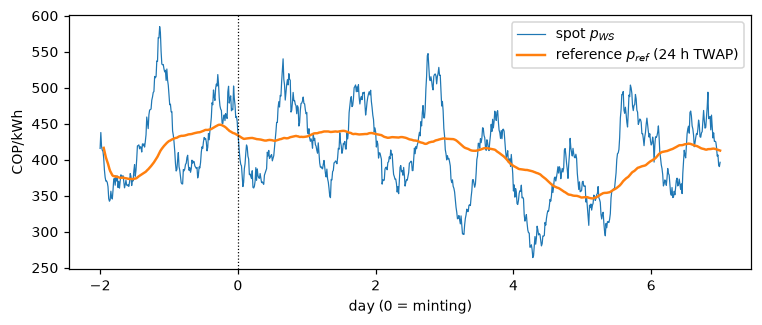

In [3]:
seed0 = int(trajectory_seeds(P)[0])          # trajectory 0 of the paper
t_h, spot = simulate_spot(seed0, P)
p_ref = reference_price_series(t_h, spot, P)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t_h/24, spot, lw=0.8, label="spot $p_{WS}$")
ax.plot(t_h/24, p_ref, lw=1.6, label="reference $p_{ref}$ (24 h TWAP)")
ax.axvline(0, color="k", ls=":", lw=0.8); ax.set_xlabel("day (0 = minting)"); ax.set_ylabel("COP/kWh"); ax.legend()
print(f"trajectory 0 seed = {seed0};  p_ref(0) = {p_ref[P.n_history]:.1f} COP/kWh")

### Why the breaker clips instead of rejecting

A breaker that *rejects* observations more than 30 % away from the last accepted one locks onto a stale
value under a sustained move (Section 6.2). The rate-limiting breaker follows the move at 30 %/h.

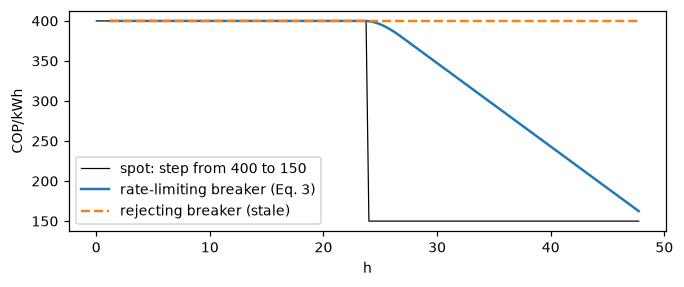

In [4]:
t_demo = np.arange(0, 48, P.dt_h); s_demo = np.where(t_demo < 24, 400.0, 150.0)
pr_rate = reference_price_series(t_demo, s_demo, P)
pr_rej  = reference_price_series(t_demo, s_demo, P, oracle_cls=RejectingBreaker)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.plot(t_demo, s_demo, "k", lw=0.8, label="spot: step from 400 to 150")
ax.plot(t_demo, pr_rate, lw=1.6, label="rate-limiting breaker (Eq. 3)")
ax.plot(t_demo, pr_rej, lw=1.6, ls="--", label="rejecting breaker (stale)")
ax.set_xlabel("h"); ax.set_ylabel("COP/kWh"); ax.legend();

## 3. One position on one price path

At $t=0$ the position pledges $E_{\mathrm{col}} = \sigma(0)\,C^0 = 5$ kWh and mints
$\ell\$ = E_{\mathrm{col}}\,p_{\mathrm{ref}}(0)/\rho_0$ with $\rho_0 = \alpha_{\min} = 1.50$.
Each step: the debt index accrues (Eq. 5), the oracle admits the new spot, the ratio
$\rho = E_{\mathrm{col}}\,p_{\mathrm{ref}}/\ell\$$ (Eq. 4) is evaluated, and the position is liquidated if
$\rho < \alpha_\ell$, the liquidator receiving $E_{\mathrm{rec}} = \min\{E_{\mathrm{col}},\, \ell\$(1+\beta_\ell)/p_{\mathrm{ref}}\}$ (Eq. 6).

debt minted: 1446.8 COP
liquidated: True | at day 4.62 | rho at liquidation: 1.2492
conservative liquidated: False | min rho: 1.856


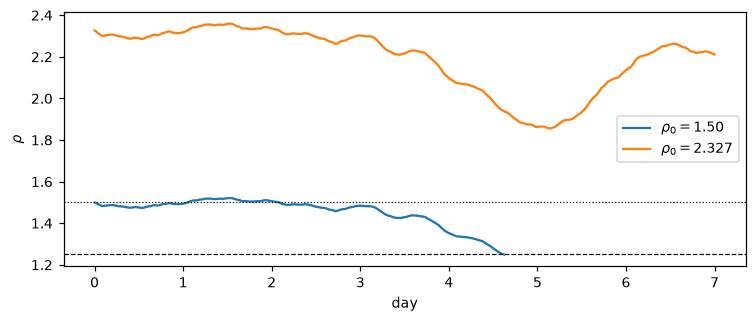

In [5]:
r = run_trajectory(seed0, P, rho0=P.rho0)
rc = run_trajectory(seed0, P, rho0=P.rho0_conservative)
fig, ax = plt.subplots(figsize=(8, 3))
for res, lab in ((r, r"$\rho_0=1.50$"), (rc, r"$\rho_0=2.327$")):
    rho = np.where(np.isinf(res.rho), np.nan, res.rho); ax.plot(res.t_h/24, rho, label=lab)
ax.axhline(P.alpha_min, color="k", ls=":", lw=0.8); ax.axhline(P.alpha_liq, color="k", ls="--", lw=0.8)
ax.set_xlabel("day"); ax.set_ylabel(r"$\rho$"); ax.legend()
print("debt minted:", round(r.debt0, 1), "COP")
print("liquidated:", r.liquidated, "| at day", round(r.liquidation.t_h/24, 2) if r.liquidation else None,
      "| rho at liquidation:", round(r.liquidation.rho, 4) if r.liquidation else None)
print("conservative liquidated:", rc.liquidated, "| min rho:", round(rc.min_rho, 3))

## 4. The price envelope — 500 trajectories (Section 5.2, Table 2)

Seeds come from a parent generator seeded at 20260527. Expect about 2–3 % of positions at the
permitted leverage to be liquidated in an ordinary week, a fifth-percentile minimum ratio of 1.265,
and no liquidation with a shortfall. The conservative position is never liquidated.
(About 10 s per batch.)

In [6]:
t0 = time.time()
base = run_batch(P, rho0=P.rho0)
cons = run_batch(P, rho0=P.rho0_conservative)
print(f"{time.time()-t0:.1f} s")
pd.DataFrame({k: batch_summary(v, P) for k, v in (("rho0 = 1.50", base), ("rho0 = 2.327", cons))}).drop(["invariants_held"])

7.1 s


,rho0 = 1.50,rho0 = 2.327
n,500,500
rho0,1.5,2.327
liquidated,15,0
liquidated_pct,3.0,0.0
shortfalls,0,0
unprofitable,4,0
rho_min_p05,1.264674,1.96193
rho_min_min,1.246607,1.842131
rho_at_liq_range,"(1.246607, 1.249987)","(None, None)"
pref_fall_max,0.207867,0.207867


In [7]:
inv = pd.DataFrame({"rho0 = 1.50": batch_summary(base, P)["invariants_held"],
                    "rho0 = 2.327": batch_summary(cons, P)["invariants_held"]})
inv.index.name = "invariant (trajectories in which it held, of 500)"; inv

,rho0 = 1.50,rho0 = 2.327
"invariant (trajectories in which it held, of 500)",,
I1,12,500
I2,500,500
I3,500,500
I4,500,500
I5,500,500
I6,500,500
I7,500,500
I8,500,500


I1 is breached in almost every trajectory at $\rho_0 = 1.50$: minted exactly at $\alpha_{\min}$, the first
downward move of $p_{\mathrm{ref}}$ (or the first accrual of the debt index) carries the position below it, and the
protocol defines no action between $\alpha_{\min}$ and $\alpha_\ell$. The conservative position never breaches it.

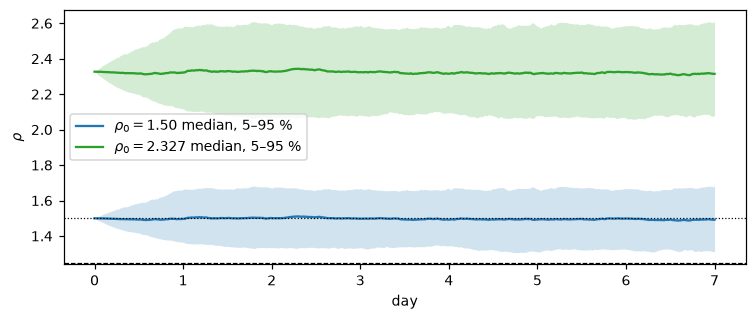

In [8]:
def band(results):
    a = np.array([res.rho for res in results])
    for row in a:
        k = np.flatnonzero(np.isinf(row))
        if k.size: row[k] = row[k[0]-1]
    return np.percentile(a, 5, axis=0), np.median(a, axis=0), np.percentile(a, 95, axis=0)
t_d = base[0].t_h/24
fig, ax = plt.subplots(figsize=(8, 3))
for res, c, lab in ((base, "C0", r"$\rho_0=1.50$"), (cons, "C2", r"$\rho_0=2.327$")):
    lo, med, hi = band(res); ax.fill_between(t_d, lo, hi, color=c, alpha=0.2, lw=0); ax.plot(t_d, med, color=c, label=lab+" median, 5–95 %")
ax.axhline(P.alpha_min, color="k", ls=":", lw=0.8); ax.axhline(P.alpha_liq, color="k", ls="--", lw=0.8)
ax.set_xlabel("day"); ax.set_ylabel(r"$\rho$"); ax.legend();

## 5. Where the envelope ends — the shock sweep (Section 5.3)

A permanent multiplicative shock to the price target at day 3.5. A liquidation at $\alpha_{\min}$ needs a fall
of $1-\alpha_\ell/\alpha_{\min} = 16.7\,\%$ of $p_{\mathrm{ref}}$; the conservative position needs falls three times as large.
The premium $\beta_\ell$ is stated at $p_{\mathrm{ref}}$ while the liquidator sells at the spot, which during a fall lies
below the 24-hour average — so many liquidations are **unprofitable** for the liquidator. (About 10 s per shock level;
the cell below runs a reduced grid — `scripts/run_shock_sweep.py` runs the full one.)

In [9]:
rows = []
for rho0, shocks in ((P.rho0, [-0.05, -0.15, -0.30]), (P.rho0_conservative, [-0.35, -0.45])):
    for s in shocks:
        res = run_batch(P, rho0=rho0, shock=s, shock_day=3.5)
        liqs = [x.liquidation for x in res if x.liquidation]
        rows.append(dict(rho0=rho0, shock_pct=100*s, liquidated_pct=100*len(liqs)/len(res),
                         unprofitable_pct_of_liq=100*sum(l.unprofitable for l in liqs)/max(1,len(liqs)),
                         shortfalls=sum(l.shortfall>0 for l in liqs),
                         rho_at_liq=(min(l.rho for l in liqs), max(l.rho for l in liqs)) if liqs else None))
pd.DataFrame(rows)

,rho0,shock_pct,liquidated_pct,unprofitable_pct_of_liq,shortfalls,rho_at_liq
0,1.500,-5.0,13.0,33.846154,0,"(1.246607, 1.249999)"
1,1.500,-15.0,73.8,52.032520,0,"(1.244628, 1.249997)"
2,1.500,-30.0,100.0,80.800000,0,"(1.240327, 1.249999)"
3,2.327,-35.0,0.8,0.000000,0,"(1.248948, 1.249812)"
4,2.327,-45.0,71.6,45.810056,0,"(1.235277, 1.249996)"


## 6. The collateral channel — evening discharge (Section 5.4, Table 3)

Invariant I8 makes the second channel measurable: discharging the battery releases pledge and lowers $\rho$
with no price movement. A prosumer who discharges every evening from 18:00 to 22:00 on the price path of
trajectory 0 loses a position minted at the permitted leverage on the first evening at every power tried.
Above the power at which one 15-minute step removes $(\alpha_\ell - 1)\,\ell\$/p_{\mathrm{ref}}$ — about 3.2 kW —
a single step can carry $\rho$ from above $\alpha_\ell$ to below 1, i.e. liquidation **with bad debt**.

In [10]:
rows = []
for rho0 in (P.rho0, P.rho0_conservative):
    for kW in (0.5, 1, 2, 3, 5, 8):
        res = run_trajectory(seed0, P, rho0=rho0, dispatch=evening_discharge(kW))
        l = res.liquidation
        rows.append(dict(rho0=rho0, power_kW=kW, kWh_per_step=round(kW*P.dt_h/P.eta_d, 2),
                         liquidation_hour=(l.t_h if l else None), rho_at_liq=(round(l.rho, 3) if l else None),
                         shortfall_pct=(round(l.shortfall_pct, 1) if l else 0.0)))
debt = base[0].E_col[0]*base[0].p_ref0/P.rho0
print(f"one-step critical power at rho0=1.50: {(P.alpha_liq-1)*debt/base[0].p_ref0*P.eta_d/P.dt_h:.2f} kW")
pd.DataFrame(rows)

one-step critical power at rho0=1.50: 3.17 kW


,rho0,power_kW,kWh_per_step,liquidation_hour,rho_at_liq,shortfall_pct
0,1.500,0.5,0.13,19.50,1.220,0.0
1,1.500,1.0,0.26,18.75,1.178,0.0
2,1.500,2.0,0.53,18.25,1.177,0.0
3,1.500,3.0,0.79,18.25,1.020,0.0
4,1.500,5.0,1.32,18.00,1.097,0.0
5,1.500,8.0,2.11,18.00,0.862,13.8
6,2.327,0.5,0.13,42.25,1.228,0.0
7,2.327,1.0,0.26,20.00,1.222,0.0
8,2.327,2.0,0.53,19.00,1.097,0.0
9,2.327,3.0,0.79,18.50,1.218,0.0


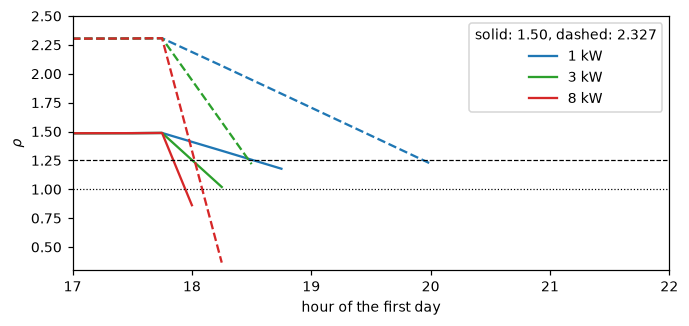

In [11]:
fig, ax = plt.subplots(figsize=(7, 3))
for kW, c in ((1, "C0"), (3, "C2"), (8, "C3")):
    for rho0, ls in ((P.rho0, "-"), (P.rho0_conservative, "--")):
        res = run_trajectory(seed0, P, rho0=rho0, dispatch=evening_discharge(kW))
        ax.plot(res.t_h, np.where(np.isinf(res.rho), np.nan, res.rho), ls=ls, color=c, label=f"{kW} kW" if ls=="-" else None)
ax.axhline(P.alpha_liq, color="k", ls="--", lw=0.8); ax.axhline(1, color="k", ls=":", lw=0.8)
ax.set_xlim(17, 22); ax.set_ylim(0.3, 2.5); ax.set_xlabel("hour of the first day"); ax.set_ylabel(r"$\rho$"); ax.legend(title="solid: 1.50, dashed: 2.327");

## 7. The eight invariants

| | Kind | What can falsify it |
|---|---|---|
| I1 global solvency | dynamic | a fall in $p_{\mathrm{ref}}$ |
| I2 liquidator viability | static | parameter choice only |
| I3 monotone debt index | construction | — |
| I4 surplus buffer | dynamic | a liquidation with a shortfall |
| I5 dynamic threshold | construction | — |
| I6 reserve floor | construction | — |
| I7 parity band | construction | — |
| I8 physical backing | dynamic | discharge or capacity fade |

I4 and I8 are exercised together in the discharge experiment: at 8 kW the pledge leaves the battery faster
than the position is evaluated, the liquidation clears at $\rho < 1$ and the shortfall is charged to the buffer.

In [12]:
res = run_trajectory(seed0, P, rho0=P.rho0, dispatch=evening_discharge(8.0))
pd.Series(res.invariants, name="held").to_frame().assign(first_breach_step=pd.Series(res.first_breach))

,held,first_breach_step
I1,False,1.0
I2,True,NaN
I3,True,NaN
I4,False,72.0
I5,True,NaN
I6,True,NaN
I7,True,NaN
I8,True,NaN


## Reproducing the paper's tables and figures

```bash
python scripts/run_all.py        # ~2 min: Table 2, shock sweep, Table 3, Fig. 2, Fig. 3 -> results/
pytest tests                     # unit and regression tests
```